# A First Look at LLMs with Ollama

In this notebook, we will use a locally served Ollama model to look at two basic ideas behind large language models (LLMs): how text can be split into tokens, and how a model predicts what token may come next.

We will start with a small, illustrative comparison of word-level tokenization and byte-pair encoding (BPE). Then we will ask Ollama to continue `One,two,three,` and display the most likely next-token alternatives with their probabilities. The notebook is intentionally short; the goal is to make the basic ideas visible, not to inspect every internal detail of the model.

## Before we begin

Start a GPU interactive session as described in `README.md` and `ollama-demo.pdf`. In a terminal on the allocated compute node, load Ollama, choose a port, and start the server. For example:

```bash
module load Ollama
export OLLAMA_HOST=127.0.0.1:40063
ollama serve
```

In another shell on the same node, pull the small model used below if it is not already available:

```bash
ollama pull llama3.2:1b
```

Leave the server running while you use this notebook. If you chose a different port or model, update the settings in the next cell. The notebook uses Python's standard library for API calls and `pandas`/`matplotlib` for readable tables and simple plots.

Keep the notebook and its `utils/` folder together, and launch Jupyter with `hpcai` as the working directory so the import works. A small helper module in `utils/ollama_demo.py` handles the HTTP request details, checks which models are installed, and builds the tables and plots. The model settings and Ollama request remain visible in the notebook; this keeps the learning steps readable without hiding what we ask the model to do.

In [ ]:
# Match this URL and model to the Ollama server you started in the terminal.
OLLAMA_HOST = "http://127.0.0.1:40063"
MODEL = "llama3.2:1b"

import math
import re

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from utils.ollama_llm_demo import generate, list_models, show_next_token_scores, show_tokenization_comparison

# Check that the local server is reachable and the selected model is installed.
models = list_models(OLLAMA_HOST)
print("Ollama is reachable.")
print("Installed models:", ", ".join(models) if models else "none")
if MODEL not in models:
    raise ValueError(f"{MODEL!r} is not installed. Pull it in the terminal or change MODEL above.")


## 1. From words to tokens

People naturally read text as words. A simple word-level tokenizer can split a sentence into words and punctuation. Language models instead use a model-specific vocabulary; with byte-pair encoding (BPE), common character sequences are merged into reusable pieces. The pieces can be complete words, subwords, punctuation, or whitespace attached to a word.

In the next cell, change `TOKENIZATION_TEXT` to a word or sentence. We compare a small, visible word-and-punctuation rule with the real `cl100k_base` BPE tokenizer from `tiktoken`. The BPE IDs are actual IDs from that encoding's vocabulary. The word-level IDs are assigned in order of first appearance in this example, since this simple tokenizer has no fixed vocabulary. Neither should be read as the IDs used by the Ollama model: Llama 3.2 has its own tokenizer.

For a more interactive view of this encoding, try the [Tiktokenizer visualizer for `cl100k_base`](https://tiktokenizer.vercel.app/?model=cl100k_base). It is an external site and shows this encoding, not the Ollama model tokenizer.


In [2]:
# Try one word, an unfamiliar word, or a complete sentence.
TOKENIZATION_TEXT = "preprocessing is useful"
tokenization = show_tokenization_comparison(TOKENIZATION_TEXT)


Input: 'preprocessing is useful'
Word-level token/ID pairs — 3 unique (IDs assigned for this example):


Token,Token ID
'preprocessing',0
'is',1
'useful',2


BPE token/ID pairs using cl100k_base — 4 unique:


Token,Token ID
'pre',1762
'processing',21315
' is',374
' useful',5505


### Note

Compare the number and boundaries of the pieces. The word-level rule keeps each word intact and separates punctuation; BPE may split a word into smaller pieces and represents spaces as part of token pieces. A tokenizer's integer IDs are vocabulary indices, not measurements of meaning. Each table lists unique token/ID pairs once, so repeated pieces appear only once. The BPE IDs shown here are real for `cl100k_base`, but a different model can use different pieces and IDs.

Ollama's generation API reports a prompt token **count**, but does not expose the tokenizer's full segmentation or candidate token IDs. In the next exercise we will use Ollama's own prompt count and next-token scores.


In [4]:
from _educational import *

data = """
Machine learning is a field of artificial intelligence.
Natural language processing enables computers to understand text.
Tokenization breaks text into smaller units called tokens.
Byte pair encoding learns frequently occurring character sequences.
"""

enc = train_simple_encoding(
    data,
    vocab_size=400,
    visualise="live",
    delay=0.15
)

The current most common pair is b' char' + b'ac'
So we made b' charac' our 400th token
Now the first fifty words in our training data look like:\n

Machine learning is a field of artificial intelligence
Natural language processing enables computers to understand text
Tokenization breaks text into smaller units called tokens
Byte pair encoding learns frequently occurring character sequences

\nTraining complete.
Final vocabulary size: 400


## 2. Predicting the next token

Now we will give the model the prefix `One,two,three,` and ask for exactly one continuation token. A word-and-punctuation split gives six pieces (`One`, `,`, `two`, `,`, `three`, `,`), but the Ollama model's tokenizer may count or segment them differently. The API response includes `prompt_eval_count`, which reports the number of prompt tokens evaluated.

We also request the top 10 next-token alternatives and their log probabilities from Ollama's `/api/generate` endpoint. The helper requests log probabilities and a complete, non-streamed response automatically; these are fixed for this exercise. We convert each log probability to a probability with `exp(logprob)`. The listed probabilities are **not expected to sum to 100%**, because we show only the top 10 alternatives.

**Token ID limitation:** Ollama returns the candidate token text and log probability, but not the candidate token ID. Exact IDs require access to the tokenizer vocabulary for this specific model. This cell therefore displays the real token strings and probabilities and leaves out IDs rather than substituting IDs from a different tokenizer. See the [Ollama generate API](https://github.com/ollama/ollama/blob/main/docs/api.md) for the `logprobs` and `top_logprobs` request fields.


Ollama prompt token count: 7
Selected next token: ' four'


Token,Probability (%),Log probability,Selected
' four',12.99,-2.041,True
'we',5.75,-2.856,False
'Four',4.10,-3.193,False
' and',3.15,-3.459,False
'let',2.83,-3.566,False
'there',2.76,-3.589,False
'that',2.17,-3.829,False
'all',1.98,-3.923,False
' Four',1.85,-3.992,False
' let',1.59,-4.139,False


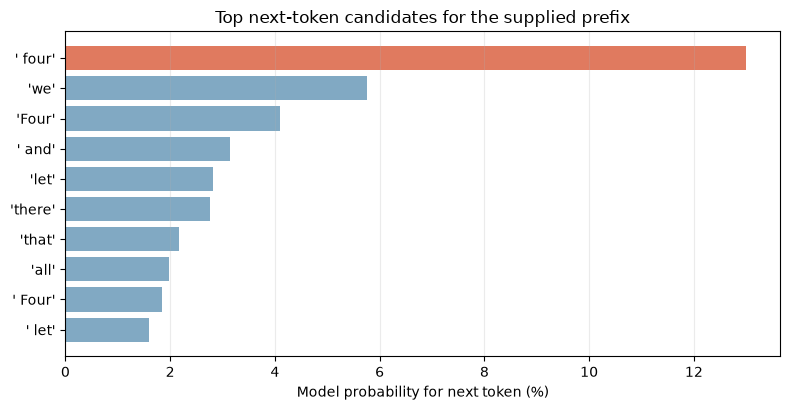

In [3]:
NEXT_TEXT = "One,two,three,"

# Ask Ollama to continue the exact prefix by one token and return alternatives.
result = generate(OLLAMA_HOST, {
    "model": MODEL,
    "prompt": NEXT_TEXT,
    "raw": True,
    "keep_alive": "10m",
    "top_logprobs": 10,
    "options": {"num_predict": 1, "temperature": 0},
})
print("\nOllama prompt token count:", result.get("prompt_eval_count", "not reported"))
print("Selected next token:", repr(result.get("response", "")))
next_token_table = show_next_token_scores(result)


### Note

The model scores possible next tokens in context; it does not search for a stored “next word.” The top candidate may look like a word, a punctuation mark, or a piece that includes leading whitespace. If generation continues, the model appends a selected token to the prefix and predicts again.

Each value is the model-reported probability for one candidate token as the next token after the exact prefix shown above. Note that `temperature=0` would make Ollama choose the highest-scoring next token.

## 3. Ask the model a question

With `raw=False` Ollama applies the model’s chat template, and the model returns a concise answer, as a typical Q and A. With `raw=True`, it treats the prompt as plain continuation text and continues into a longer FAQ, despite the “one sentence” instruction.


In [39]:
CHAT_PROMPT = "In one sentence, why might a researcher use a locally hosted LLM as opposed to a cloud hosted LLM?"

chat_result = generate(OLLAMA_HOST, {
    "model": MODEL,
    "prompt": CHAT_PROMPT,
    "raw": False,
    "options": {"num_predict": 200, "temperature": 0.7},
})
print('Setting raw=False:\n')
print(chat_result.get("response", "").strip())


chat_result = generate(OLLAMA_HOST, {
    "model": MODEL,
    "prompt": CHAT_PROMPT,
    "raw": True,
    "options": {"num_predict": 200, "temperature": 0.7},
})
print('\n\nSetting raw=True:\n')
print(chat_result.get("response", "").strip())

Setting raw=False:

A researcher may choose to use a locally hosted Large Language Model (LLM) instead of a cloud-hosted LLM if they require more control over the infrastructure, data storage, and scaling options, or need to integrate with specific local systems or applications.


Setting raw=True:

## Step 1: Consider the benefits of local hosting
A locally hosted Large Language Model (LLM) offers several advantages. It allows for more control over the data and environment in which the model is trained and deployed, potentially leading to better results due to more efficient use of resources.

## Step 2: Consider the limitations of cloud hosting
On the other hand, using a cloud-hosted LLM has its own set of benefits. Cloud services typically offer scalability, flexibility, and cost-effectiveness, which can be beneficial for large-scale models or models that require significant computational power.

## Step 3: Evaluate the trade-offs between the two options
When evaluating whether to u